# 기본 04 · 이미지와 질문 메시지 구성

`04_messages.py`의 B05 구현을 단계별로 살펴봅니다. 문서 `doc01` 이미지에 날짜·공급자·총액 질문을 하나씩 연결하고, 제공된 모의 응답과 근거를 함께 정리합니다.

저장소 내부에서 Python 커널로 위에서 아래로 실행하세요. 이미지와 구조 시각화에는 Matplotlib, IPython이 필요합니다. 파일은 읽기만 하며 마지막 저장 셀은 선택 사항입니다.

## 1. 실습 요구사항과 입력

README는 `role=user`, `content` 안에 `image/path`와 `text/text` 항목을 구성하도록 요구합니다. 현재 구현은 메시지를 목록으로 만들고 각 content 항목을 `type`으로 구분합니다. 이는 실습용 구조이며 특정 VLM API의 공식 입력 규격을 의미하지 않습니다.

이미지를 질문마다 새로 추론하는 것이 아니라 이미지 경로와 질문 문자열을 Python 자료구조로 구성합니다. 답변은 `lesson.json`에 이미 들어 있습니다.


In [1]:
from pathlib import Path
import json
import textwrap
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from IPython.display import display

start = Path.cwd().resolve()
project = next((p for p in [start, *start.parents]
                if (p / '20261109/01_basic/04_messages.py').is_file()), None)
if project is None:
    raise FileNotFoundError('저장소 내부에서 실행하세요.')
base = project / '20261109/01_basic'
lesson = json.loads((base / 'lesson.json').read_text(encoding='utf-8'))
doc = lesson['documents']['doc01']
print('입력 이미지:', doc['file'])
for field, question in lesson['questions'].items():
    print(field, '->', question)


입력 이미지: doc01.png
issued_at -> What is the issue date?
supplier -> Who is the supplier?
total_amount -> What is the total in KRW?


## 2. 이미지와 질문 3개 확인

동일한 이미지에 발행일·공급자·총액 질문을 각각 연결합니다. 아래 표시는 사람이 입력을 확인하기 위한 것으로 모델 호출이 아닙니다.


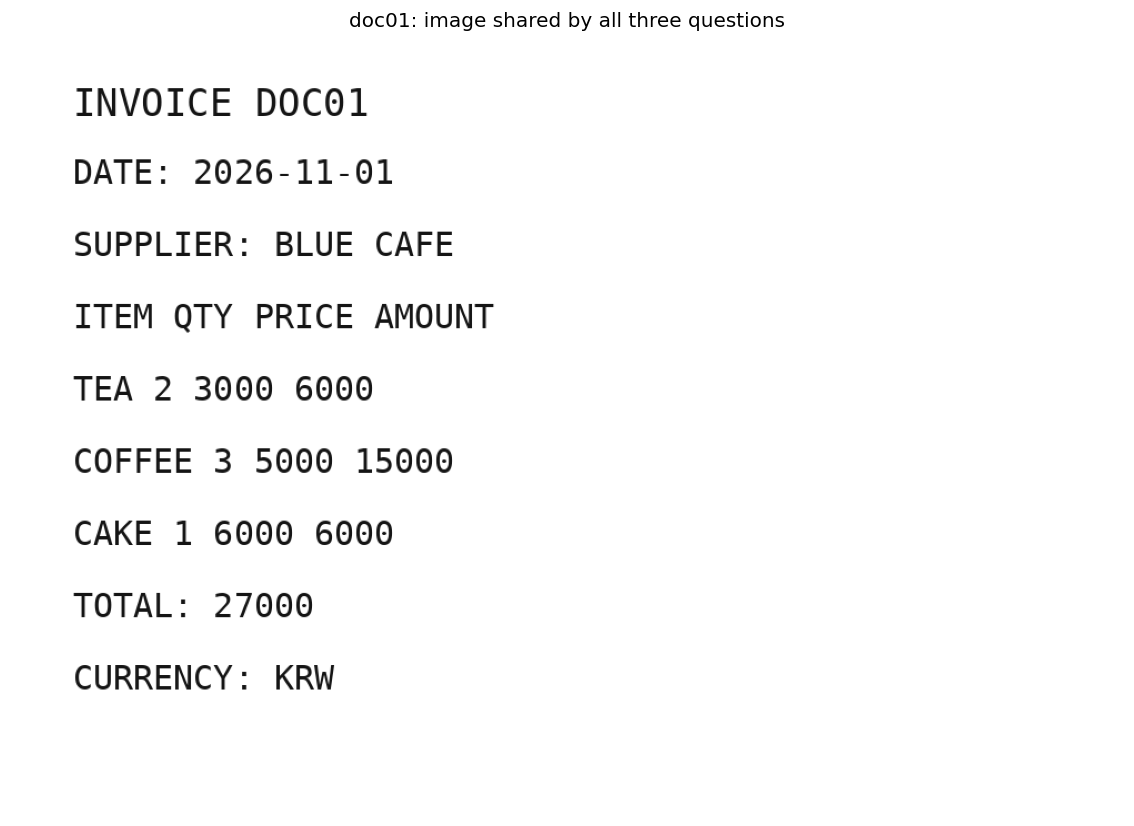

In [2]:
fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(mpimg.imread(base / doc['file']))
ax.set_title('doc01: image shared by all three questions')
ax.axis('off')
fig.tight_layout()
display(fig)
plt.close(fig)


## 3. 현재 B05 구현으로 메시지 생성

원본 파일의 B05 블록을 읽어 실행합니다. 응답의 `field`로 질문을 찾은 뒤, 이미지 경로와 질문을 `content` 목록에 넣습니다. `messages`는 질문마다 하나의 사용자 메시지를 담는 목록입니다. 반복문이 끝나면 `rows`에는 질문별 레코드 3개가 생깁니다.

| 키 | 의미 |
|---|---|
| `role` | 메시지 작성자: `user` |
| `content[0].type` / `path` | 이미지 항목과 로컬 이미지 경로 |
| `content[1].type` / `text` | 텍스트 항목과 질문 문자열 |
| `response` | 제공 응답 전체: `field`, `answer`, `evidence` |
| `backend` | 실제 추론이 아닌 `mock` |
| `model_id`, `inference_ms` | 모델 실행 정보가 없으므로 `None` |

`path`는 문자열이며 이미지 바이트를 담지 않습니다. 외부 서비스로 전달할 때는 해당 서비스의 이미지 업로드·URL·인코딩 규격에 맞춰 변환해야 합니다.


In [3]:
source = (base / '04_messages.py').read_text(encoding='utf-8')
block = textwrap.dedent(source.split('# TODO B05', 1)[1].split('# TODO 끝 B05', 1)[0])
print('현재 B05 구현:')
print(block.strip())
rows = []
for answer in doc['mock_vlm']['responses']:
    question = lesson['questions'][answer['field']]
    scope = {'base': base, 'doc': doc, 'question': question}
    exec(compile(block, str(base / '04_messages.py'), 'exec'), scope)
    messages = scope['messages']
    rows.append({'backend': 'mock', 'messages': messages, 'response': answer,
                 'model_id': None, 'inference_ms': None})
    print(question, '->', answer['answer'])


현재 B05 구현:
messages = [
    {
        'role': 'user',
        'content': [
            {'type': 'image', 'path': str(base / doc['file'])},
            {'type': 'text', 'text': question},
        ],
    }
]
What is the issue date? -> 2026-11-01
Who is the supplier? -> BLUE CAFE
What is the total in KRW? -> 27000


## 4. 메시지와 응답의 연결 시각화

왼쪽 이미지는 각 질문에 공통으로 사용됩니다. 오른쪽은 새로 생성된 모델 출력이 아니라 제공된 모의 답과 근거입니다. 영문 표기는 별도의 한글 폰트 없이 표시하기 위한 것입니다.


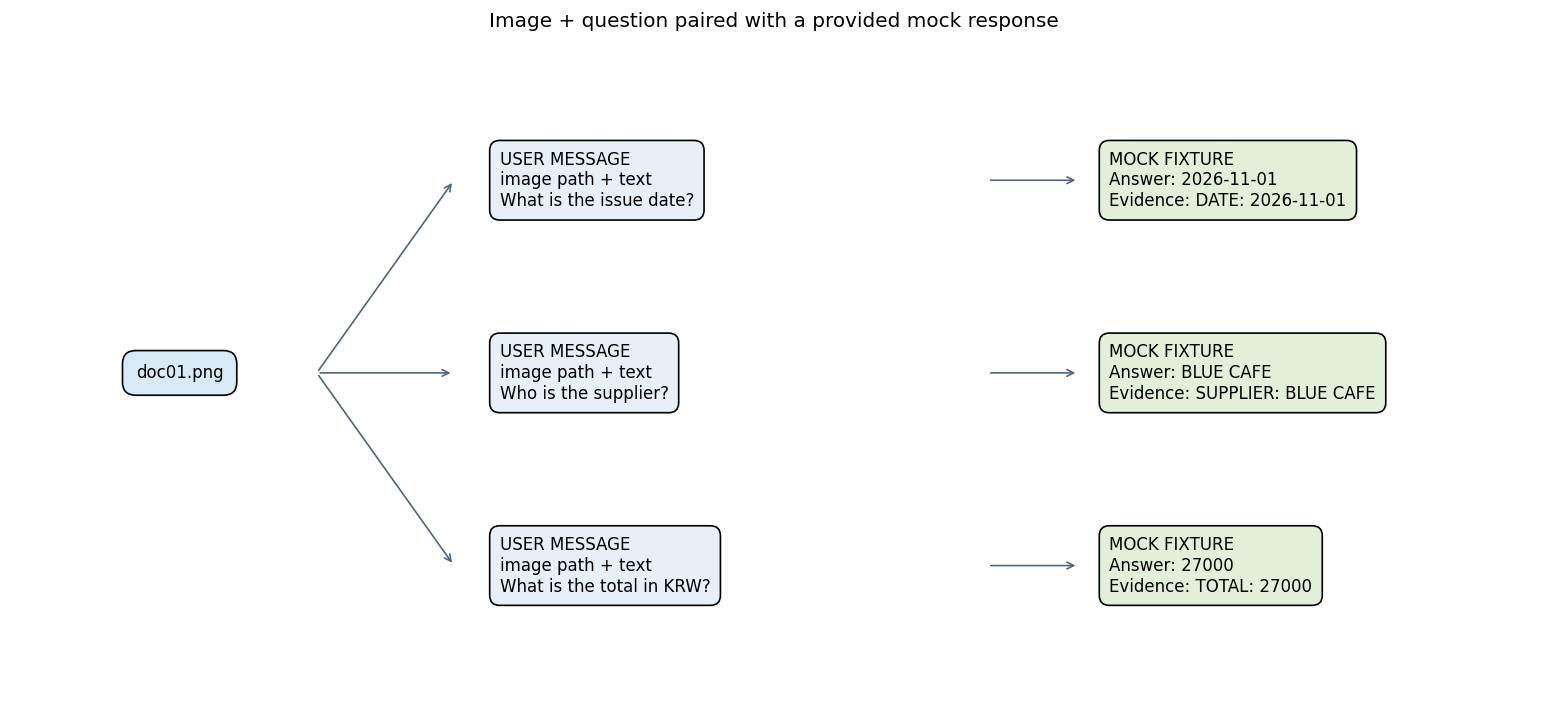

In [4]:
fig, ax = plt.subplots(figsize=(13, 6))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis('off')
ax.text(0.11, 0.50, doc['file'], ha='center', va='center',
        bbox=dict(boxstyle='round,pad=0.8', facecolor='#d9eaf7'))
for y, row in zip([0.80, 0.50, 0.20], rows):
    question = row['messages'][0]['content'][1]['text']
    response = row['response']
    ax.annotate('', xy=(0.29, y), xytext=(0.20, 0.50),
                arrowprops=dict(arrowstyle='->', color='#526777'))
    ax.text(0.32, y, 'USER MESSAGE\nimage path + text\n' + question,
            ha='left', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=0.6', facecolor='#e7eff7'))
    ax.annotate('', xy=(0.70, y), xytext=(0.64, y),
                arrowprops=dict(arrowstyle='->', color='#526777'))
    ax.text(0.72, y, 'MOCK FIXTURE\nAnswer: ' + str(response['answer']) +
            '\nEvidence: ' + response['evidence'], ha='left', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=0.6', facecolor='#e2f0d9'))
ax.set_title('Image + question paired with a provided mock response', pad=15)
fig.tight_layout()
display(fig)
plt.close(fig)


## 5. JSON 형식과 저장 내용 확인

아래는 첫 번째 레코드입니다. Python의 딕셔너리와 리스트를 `json.dumps()`로 JSON 문자열로 변환하면 `None`은 `null`이 됩니다. `answer`는 원본 데이터의 자료형을 유지하므로 날짜·공급자는 문자열, 총액은 정수입니다. 모든 답을 문자열로 변환하는 처리는 아닙니다.

한글을 그대로 출력하기 위해 `ensure_ascii=False`, 읽기 쉽게 들여쓰기하기 위해 `indent=2`를 지정합니다.


In [5]:
print(json.dumps(rows[0], ensure_ascii=False, indent=2))
payload = json.dumps(rows, ensure_ascii=False, indent=2)
restored = json.loads(payload)
assert restored == rows
assert len(restored) == 3
assert {r['response']['field'] for r in restored} == {'issued_at', 'supplier', 'total_amount'}
for row, expected in zip(restored, doc['mock_vlm']['responses']):
    message, = row['messages']
    assert message['role'] == 'user'
    image, text = message['content']
    assert image == {'type': 'image', 'path': str(base / doc['file'])}
    assert Path(image['path']).is_file()
    assert text == {'type': 'text', 'text': lesson['questions'][expected['field']]}
    assert row['response'] == expected
    assert row['backend'] == 'mock'
    assert row['model_id'] is None and row['inference_ms'] is None
print('검증 통과: 질문 3개 · 이미지 경로 · 제공 응답과 근거 · JSON 왕복 변환')


{
  "backend": "mock",
  "messages": [
    {
      "role": "user",
      "content": [
        {
          "type": "image",
          "path": "/home/swchoi/projects/python/practice_assignment/20261109/01_basic/doc01.png"
        },
        {
          "type": "text",
          "text": "What is the issue date?"
        }
      ]
    }
  ],
  "response": {
    "field": "issued_at",
    "answer": "2026-11-01",
    "evidence": "DATE: 2026-11-01"
  },
  "model_id": null,
  "inference_ms": null
}
검증 통과: 질문 3개 · 이미지 경로 · 제공 응답과 근거 · JSON 왕복 변환


## 6. 선택: 결과 저장

원본 스크립트는 `p04_mock_answers.json`을 생성하거나 덮어씁니다. 아래 주석을 해제하면 같은 위치와 형식으로 저장하고 다시 읽어 확인할 수 있습니다. 생성한 출력 JSON은 커밋 대상에서 제외합니다.


In [6]:
# output_path = base / 'p04_mock_answers.json'
# output_path.write_text(payload, encoding='utf-8')
# assert json.loads(output_path.read_text(encoding='utf-8')) == rows
# print('저장 및 재읽기 완료:', output_path.name)


## 7. 설명 질문과 응용 04와의 차이

**이 파일만 실행했을 때 모델 정확도나 GPU 처리시간을 보고해도 될까요?** 아니요. 모델을 호출하지 않고 교사가 작성한 응답을 읽으므로 모델 정확도나 추론시간을 측정한 것이 아닙니다. 코드 실행시간도 GPU 추론시간으로 해석할 수 없습니다.

기본 04는 **메시지를 구성하고 제공 응답·근거를 보존**합니다. 근거가 OCR 원문에 존재하는지는 검사하지 않습니다. 응용 04에서는 `answer['evidence'] in doc['ocr']['text']`를 사용해 그 존재 여부를 추가로 검사합니다.
